# EDA del grafo de Internet - Subgrafos regionales

Filtrando por pais y por región, chequear conectividad, largos de camino, etc.

In [2]:
import networkx as nx

G = nx.read_gml('../fetch/topology-202504-month-FULL.gml')

In [3]:
# Chequeo básico
print(f"El grafo cargado de Internet es conexo: {nx.is_connected(G)}")

El grafo cargado de Internet es conexo: True


In [4]:
# Algunos shortest paths

nx.shortest_path(G, source='1797', target='3356')

['1797', '6057', '3356']

In [23]:
# Cargar los ASmuy conectados

ases_muy_conectados = []

with open("../fetch/topology-202504-month-tier5k.txt") as f1:
    adj = f1.readlines()

for x in adj:
    x = x.strip()
    (asn1, asn2) = x.split(" ")
    ases_muy_conectados.append(asn1.lstrip('0'))
    ases_muy_conectados.append(asn2.lstrip('0'))

ases_muy_conectados = list(set(ases_muy_conectados))

print(f"Highly connected ases loaded. Total: {len(ases_muy_conectados)}")

for a in range(10):
    print(f"AS: {ases_muy_conectados[a]}")

Highly connected ases loaded. Total: 16
AS: 14840
AS: 57463
AS: 36236
AS: 35280
AS: 1239
AS: 6939
AS: 199524
AS: 37721
AS: 24482
AS: 49544


Average length: 2.31
Median length: 2.0


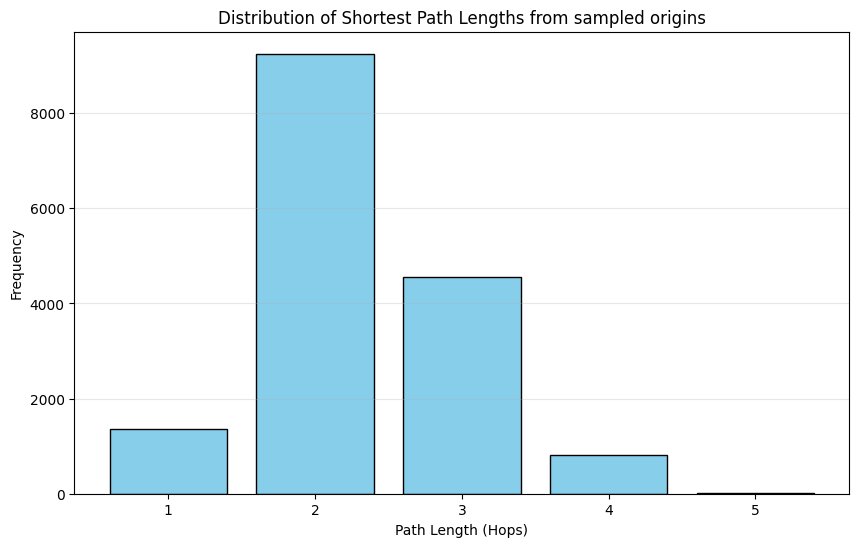

In [24]:
## Histograma

import random
import statistics as stat
import networkx as nx
import matplotlib.pyplot as plt
from collections import Counter

def get_random_sample(filename, k):
    """Memory-efficient way to sample lines from a large file."""
    with open(filename, 'r') as file:
        # Using list(file) is faster for medium files, 
        # but for massive files, consider reservoir sampling.
        lines = file.readlines()
        return random.sample(lines, min(k, len(lines)))

# Configuration
# SOURCE_NODE = '262159'
SAMPLE_SIZE = 1000
FILE_PATH = '../fetch/unique-asns-2025.txt'

# 1. Get sample and calculate lengths
sample = get_random_sample(FILE_PATH, SAMPLE_SIZE)
path_lengths = []

for src in ases_muy_conectados:
    SOURCE_NODE = src.strip().lstrip('0')
    for line in sample:
        target = line.strip().lstrip('0')
        if SOURCE_NODE == target:
            continue
        try:
            # nx.shortest_path_length is slightly faster than len(nx.shortest_path)
            length = nx.shortest_path_length(G, source=SOURCE_NODE, target=target)
            path_lengths.append(length)
        except nx.NetworkXNoPath:
            print(f"No path found for target: {target}")
        except nx.NodeNotFound:
            continue

# 2. Statistics
if path_lengths:
    print(f"Average length: {stat.mean(path_lengths):.2f}")
    print(f"Median length: {stat.median(path_lengths)}")

    # 3. Build the Histogram
    plt.figure(figsize=(10, 6))
    
    # Calculate bins based on the range of lengths
    bins = range(min(path_lengths), max(path_lengths) + 2)
    
    plt.hist(path_lengths, bins=bins, align='left', rwidth=0.8, color='skyblue', edgecolor='black')
    
    plt.title(f'Distribution of Shortest Path Lengths from sampled origins')
    plt.xlabel('Path Length (Hops)')
    plt.ylabel('Frequency')
    plt.xticks(bins[:-1])
    plt.grid(axis='y', alpha=0.3)
    
    plt.show()
else:
    print("No valid paths were found to sample.")